# Transfer-factor decomposition — do student-base animal priors explain cross-init transfer?

**The focus-20 campaign.** 20 fixed teacher recipes (one list, shared across animals *by design*)
are each cross-distilled into 6 PolyPythias student bases at 20 shared student-HP cells, for
**dog / cat / lion / pig**. Some (animal × student-base) cells transfer the trait well; others do
not. This notebook decomposes that pattern into interpretable factor groups and asks whether the
measured student-base *prior* — how much a base already likes an animal — explains it.

**The five factors:**

1. **Teacher imprint** — how strongly the teacher recipe carries the trait. A property of the
   *animal* (teacher list is identical across animals) ⇒ absorbed by an **animal fixed effect**
   (which also absorbs the *teacher-base* prior, since all teachers share pythia-160m).
2. **Teacher-base prior** — animal-level, folded into the animal FE (factor 1).
3. **Student-base prior `P_s(a)`** — a *measured* animal×base covariate; NOT absorbed by either FE
   and identified by the **within-animal cross-base contrast** (does base *s* over-perform its own
   average exactly on the animals it already favors?). Its coefficient `β` is the estimand of
   interest.
4. **ds-vs-ws structure** — do data-seed and weight-seed bases differ as *groups* after adjustment?
5. **Individual base quirks** — per-base fixed effects with/without the prior term.

> **Reading guide.** Transfer is a *hurdle*: a seed either collapses (loses the trait) or survives
> with a graded score. We split **survival** from **conditional transfer** (mean score | survived)
> and analyse each. Primary inference on the prior is a **within-animal permutation test** — the
> parametric cluster-robust p is optimistic given only ~15 animal×base clusters. Every table/figure
> below states its **row unit, aggregation, filter, and n**. Coverage is partial (some arms are
> still draining); sections print "arm not landed yet" rather than raising, and a plain re-run
> absorbs new data.

## 0. Setup

In [1]:
from __future__ import annotations

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import transfer_factors as tf
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")  # statsmodels small-cluster / separation chatter
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

DEAD = tf.DEAD  # 0.005; re-checked per animal in §2
ANIMAL_COLORS = {"dog": "#4c78a8", "cat": "#f58518", "lion": "#54a24b", "pig": "#e45756"}

cells_df, PARAM_TAGS, META = tf.load_focus20_design(ROOT)
CELL_TAGS = list(cells_df["student_tag"])
print(f"focus-20 design: {len(cells_df)} student cells, {len(PARAM_TAGS)} shared teachers, "
      f"epochs={META['epochs']}, student_seed={META['student_seed']}")

runs = tf.load_focus_runs(OUTPUT_ROOT, PARAM_TAGS, cells_df)
cells = tf.hurdle_cells(runs, dead=DEAD)
priors = tf.load_priors(OUTPUT_ROOT)
print(f"landed: {len(runs)} seed-runs -> {len(cells)} (animal×base×teacher×cell) rows; "
      f"{int(cells['cond'].notna().sum())} have >=1 surviving seed")

focus-20 design: 20 student cells, 20 shared teachers, epochs=20, student_seed=1


landed: 5752 seed-runs -> 5599 (animal×base×teacher×cell) rows; 3553 have >=1 surviving seed


## 1. Coverage — what has landed

**Row unit:** one (animal × base). **Columns:** distinct teachers landed (target 20), distinct
focus cells landed (target 20), and total seed-runs. **Filter:** focus-20 teachers × focus-20
cells only (older-campaign cells in the same dirs are dropped by the loader). Target per arm is
20 teachers × 20 cells × 1 seed = 400 seed-runs. Missing arms simply do not appear — no blank
rows; a re-run absorbs new data.

In [2]:
cov = (runs.groupby(["animal", "base_label"])
       .agg(teachers=("teacher_tag", "nunique"),
            cells=("student_tag", "nunique"),
            seed_runs=("test", "size"))
       .reset_index())
cov["group"] = cov["base_label"].map(tf._base_group)
cov = cov.sort_values(["animal", "base_label"]).reset_index(drop=True)
n_excluded = int((~runs.empty) and 0)  # focus filter applied inside loader; report raw vs kept below
display(cov)
print(f"arms landed: {len(cov)} of {len(tf.FOCUS_ANIMALS)}×{len(tf.FOCUS_BASE_LABELS)} = "
      f"{len(tf.FOCUS_ANIMALS)*len(tf.FOCUS_BASE_LABELS)} possible")
print("per animal, bases present:")
for a in tf.FOCUS_ANIMALS:
    present = sorted(cov[cov.animal == a].base_label)
    print(f"  {a:5s}: {present if present else 'NO DATA'}")

,animal,base_label,teachers,cells,seed_runs,group
0,cat,data-seed1,20,20,400,ds
1,cat,data-seed2,10,20,200,ds
2,cat,data-seed3,10,20,200,ds
3,cat,weight-seed1,20,20,400,ws
4,cat,weight-seed2,10,20,200,ws
5,cat,weight-seed3,10,20,196,ws
6,dog,data-seed1,20,20,500,ds
7,dog,data-seed2,10,20,200,ds
8,dog,data-seed3,10,20,200,ds
9,dog,weight-seed1,20,20,444,ws


arms landed: 24 of 4×6 = 24 possible
per animal, bases present:
  dog  : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']
  cat  : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']
  lion : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']
  pig  : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']


How many non-focus cells were excluded? The loader keeps only the 20 focus cell tags; the
directories also hold larger legacy grids. We recompute the raw landed-cell count to report the
exclusion.

In [3]:
raw_counts = {}
for a in tf.FOCUS_ANIMALS:
    lineages = [(t, t, f"pythia-160m-{b}") for t in PARAM_TAGS for b in tf.FOCUS_BASE_LABELS]
    from subliminal_learning.analysis.collapse_law import load_law_runs
    _, r_all = load_law_runs(OUTPUT_ROOT, animal=a, lineages=lineages)
    if len(r_all):
        raw_counts[a] = (r_all["student_tag"].nunique(),
                         r_all[r_all.student_tag.isin(CELL_TAGS)]["student_tag"].nunique())
excl = pd.DataFrame(
    [{"animal": a, "raw_cells": rc, "focus_cells_kept": kc, "excluded": rc - kc}
     for a, (rc, kc) in raw_counts.items()])
display(excl)
print("Excluded cells are older-campaign HP grids sharing the same lineage dirs; only the 20 "
      "focus cells enter every analysis below.")

,animal,raw_cells,focus_cells_kept,excluded
0,dog,579,20,559
1,cat,117,20,97
2,lion,49,20,29
3,pig,49,20,29


Excluded cells are older-campaign HP grids sharing the same lineage dirs; only the 20 focus cells enter every analysis below.


## 2. DEAD threshold check — is 0.005 in the trough?

**Row unit:** one seed-run. **Aggregation:** histogram of `test` p(target) per animal on log-ish
bins. The DEAD line must sit in the empty trough between the dead mode and the live shoulder — the
threshold is **arm-checkable**, not inherited blind. Trough occupancy (fraction of seed-runs in the
bin straddling DEAD) is printed.

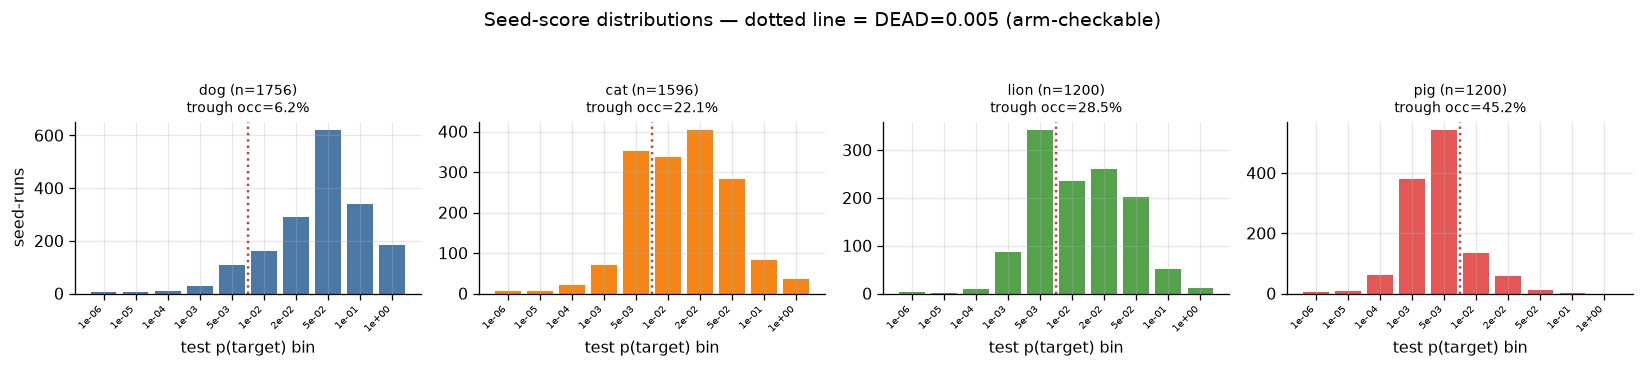

In [4]:
EDGES = [0, 1e-6, 1e-5, 1e-4, 1e-3, 5e-3, 1e-2, 2e-2, 5e-2, 1e-1, 1.0]
landed_animals = [a for a in tf.FOCUS_ANIMALS if (runs.animal == a).any()]
fig, axes = plt.subplots(1, len(landed_animals), figsize=(3.6 * len(landed_animals), 3.0),
                         squeeze=False)
for ax, a in zip(axes[0], landed_animals):
    sub = runs[runs.animal == a]
    hist = pd.cut(sub.test, EDGES, include_lowest=True).value_counts().sort_index()
    ax.bar(range(len(hist)), hist.values, color=ANIMAL_COLORS.get(a, "#888"))
    ax.set_xticks(range(len(hist)))
    ax.set_xticklabels([f"{e:.0e}" for e in EDGES[1:]], rotation=45, ha="right", fontsize=6)
    ax.axvline(hist.index.get_loc(pd.cut([DEAD], EDGES)[0]) + 0.5, color="#d03b3b", ls=":", lw=1.5)
    trough = pd.cut([DEAD], EDGES)[0]
    occ = hist[trough] / hist.sum()
    ax.set_title(f"{a} (n={len(sub)})\ntrough occ={occ:.1%}", fontsize=9)
    ax.set_xlabel("test p(target) bin")
axes[0][0].set_ylabel("seed-runs")
fig.suptitle(f"Seed-score distributions — dotted line = DEAD={DEAD} (arm-checkable)", y=1.05)
plt.tight_layout(); plt.show()

## 3. Priors — the two measured `P_s(a)`

Two measures of how much a base already likes an animal, both **per (animal × base)**:

- **logprob prior** — the base model's single-token log-probability of the animal word
  (`animal_selection/curated_scores.json`); higher = more favored.
- **behavioral prior** — the base model's own `base_p_target` on the actual eval prompts
  (favorite set); this is the exact quantity distillation must move.

These are the covariates entering §5. We show the (animal × 7-base) tables and their
cross-correlation.

In [5]:
foc = priors[priors.animal.isin(tf.FOCUS_ANIMALS)].copy()
logp_tab = foc.pivot(index="animal", columns="base_label", values="logprob_prior")
behav_tab = foc.pivot(index="animal", columns="base_label", values="behav_prior")
order = ["original"] + tf.FOCUS_BASE_LABELS
logp_tab = logp_tab.reindex(columns=[c for c in order if c in logp_tab.columns])
behav_tab = behav_tab.reindex(columns=[c for c in order if c in behav_tab.columns])
print("logprob prior — base single-token log p(animal); row=animal, col=base, higher=favored")
display(logp_tab.round(3))
print("behavioral prior — base_p_target on eval prompts; row=animal, col=base")
display(behav_tab.round(4))
m = foc.dropna(subset=["logprob_prior", "behav_prior"])
if len(m) > 2:
    from scipy.stats import pearsonr, spearmanr
    print(f"cross-measure correlation over {len(m)} (animal×base): "
          f"Pearson r={pearsonr(m.logprob_prior, m.behav_prior)[0]:.3f}, "
          f"Spearman ρ={spearmanr(m.logprob_prior, m.behav_prior)[0]:.3f}")

logprob prior — base single-token log p(animal); row=animal, col=base, higher=favored


base_label,original,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
animal,,,,,,,
cat,-4.396,-3.950,-4.216,-4.115,-4.115,-3.806,-4.787
dog,-3.533,-3.429,-3.496,-3.435,-4.934,-3.833,-4.244
lion,-4.001,-4.849,-4.540,-5.140,-4.347,-4.245,-5.257
pig,-3.729,-4.075,-4.622,-4.672,-5.266,-4.246,-4.543


behavioral prior — base_p_target on eval prompts; row=animal, col=base


base_label,original,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
animal,,,,,,,
cat,0.0036,0.0048,0.0058,0.0045,0.0053,0.0074,0.0037
dog,0.0096,0.0119,0.0111,0.0085,0.0061,0.0124,0.0064
lion,0.0062,0.0053,0.0046,0.0032,0.0044,0.0055,0.0039
pig,0.0036,0.0031,0.0021,0.0016,0.0017,0.0035,0.0023


cross-measure correlation over 28 (animal×base): Pearson r=0.695, Spearman ρ=0.650


## 4. Transfer table — survival and conditional transfer

**Row unit:** one (animal × base), aggregated over the landed teachers × cells. **Left:** survival
rate (fraction of seed-runs with test ≥ DEAD). **Right:** conditional transfer (mean test over
surviving seeds). Each cell is annotated with **n** = seed-runs behind it. Built only from landed
arms; empty arms are blank.

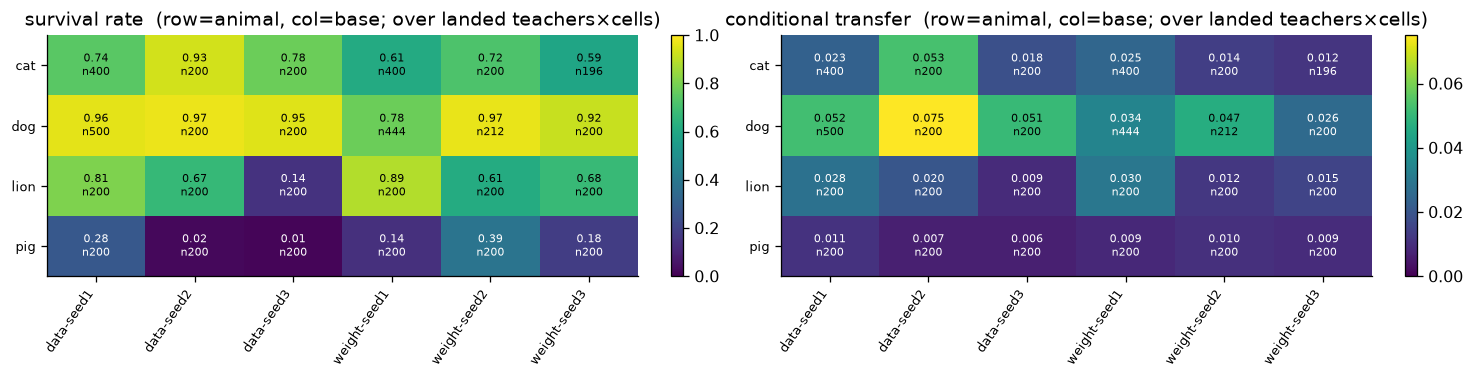

In [6]:
agg = (cells.groupby(["animal", "base_label"])
       .agg(n=("n_seeds", "sum"),
            surv=("n_alive", "sum"),
            surv_rate=("n_alive", lambda s: s.sum()),
            cond=("cond", "mean"))
       .reset_index())
# survival rate = total alive / total seeds
tot = cells.groupby(["animal", "base_label"]).agg(alive=("n_alive", "sum"),
                                                   seeds=("n_seeds", "sum")).reset_index()
agg = agg.merge(tot, on=["animal", "base_label"])
agg["surv_rate"] = agg["alive"] / agg["seeds"]

surv_p = agg.pivot(index="animal", columns="base_label", values="surv_rate")
cond_p = agg.pivot(index="animal", columns="base_label", values="cond")
n_p = agg.pivot(index="animal", columns="base_label", values="n")
cols = [c for c in tf.FOCUS_BASE_LABELS if c in surv_p.columns]
surv_p, cond_p, n_p = surv_p[cols], cond_p[cols], n_p[cols]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, tab, title, fmt in [(axes[0], surv_p, "survival rate", "{:.2f}"),
                            (axes[1], cond_p, "conditional transfer", "{:.3f}")]:
    im = aplots.annotated_heatmap(
        ax, tab, cmap="viridis", vmin=0,
        vmax=1 if title.startswith("surv") else np.nanmax(cond_p.values),
        counts=n_p, fmt=fmt, origin="upper", mid=0.6 * np.nanmax(tab.values), cell_fontsize=7)
    ax.set_title(f"{title}  (row=animal, col=base; over landed teachers×cells)")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## 5. FE + prior decomposition — does the student-base prior explain transfer?

**Row unit:** one (animal × base × teacher × cell). Response = logit of conditional transfer
(survivors only) or empirical logit of survival. Regressors: `C(animal) + C(base) + prior_z`,
weighted by surviving-seed (or total-seed) counts, **cluster-robust on the animal×base pair**. The
animal FE absorbs teacher-side effects; the base FE absorbs student quirks; `β` on the z-scored
prior is the within-animal cross-base contrast.

The **permutation test** is the primary inference (parametric p is optimistic with ~15 clusters):
residualize by animal+base FEs, aggregate to (animal×base) means, and permute the prior **within
each animal** 2000× (fixed seed).

In [7]:
fit_rows = []
perm_res = {}
for prior_col in ["logprob_prior", "behav_prior"]:
    n_avail = priors.dropna(subset=[prior_col]).merge(
        cells[["animal", "base_label"]].drop_duplicates(), on=["animal", "base_label"]).shape[0]
    if n_avail == 0:
        print(f"{prior_col}: not available for any landed arm — skipping")
        continue
    for resp in ["cond", "surv"]:
        fit = tf.fe_prior_fit(cells, priors, prior_col, response=resp)
        perm = tf.prior_permutation_test(cells, priors, prior_col, response=resp,
                                         n_perm=2000, seed=0)
        perm_res[(prior_col, resp)] = (fit, perm)
        fit_rows.append({"prior": prior_col, "response": resp, "beta": fit.beta, "se": fit.se,
                         "p_cluster": fit.p, "n": fit.nobs, "n_clusters": fit.n_clusters,
                         "perm_slope": perm["obs_slope"], "p_perm": perm["p_two_sided"]})
fit_tab = pd.DataFrame(fit_rows)
print("WLS β (z-scored prior) with cluster-robust SE + within-animal permutation p.")
print("Row unit of the fit: (animal×base×teacher×cell). p_cluster is optimistic (few clusters); "
      "p_perm is primary.")
display(fit_tab.round(4))

WLS β (z-scored prior) with cluster-robust SE + within-animal permutation p.
Row unit of the fit: (animal×base×teacher×cell). p_cluster is optimistic (few clusters); p_perm is primary.


,prior,response,beta,se,p_cluster,n,n_clusters,perm_slope,p_perm
0,logprob_prior,cond,0.1465,0.0586,0.0125,3553,24,0.0892,0.1579
1,logprob_prior,surv,0.1990,0.0847,0.0188,5599,24,0.0816,0.0840
2,behav_prior,cond,0.3392,0.0705,0.0000,3553,24,0.1019,0.0275
3,behav_prior,surv,0.2419,0.0988,0.0143,5599,24,0.0298,0.2429


**The money plot.** One marker per (animal × base): FE-residualized conditional transfer vs
the prior, colored by animal, labeled by base. A positive trend = the prior explains within-animal
cross-base differences. Verdict printed from the permutation test.

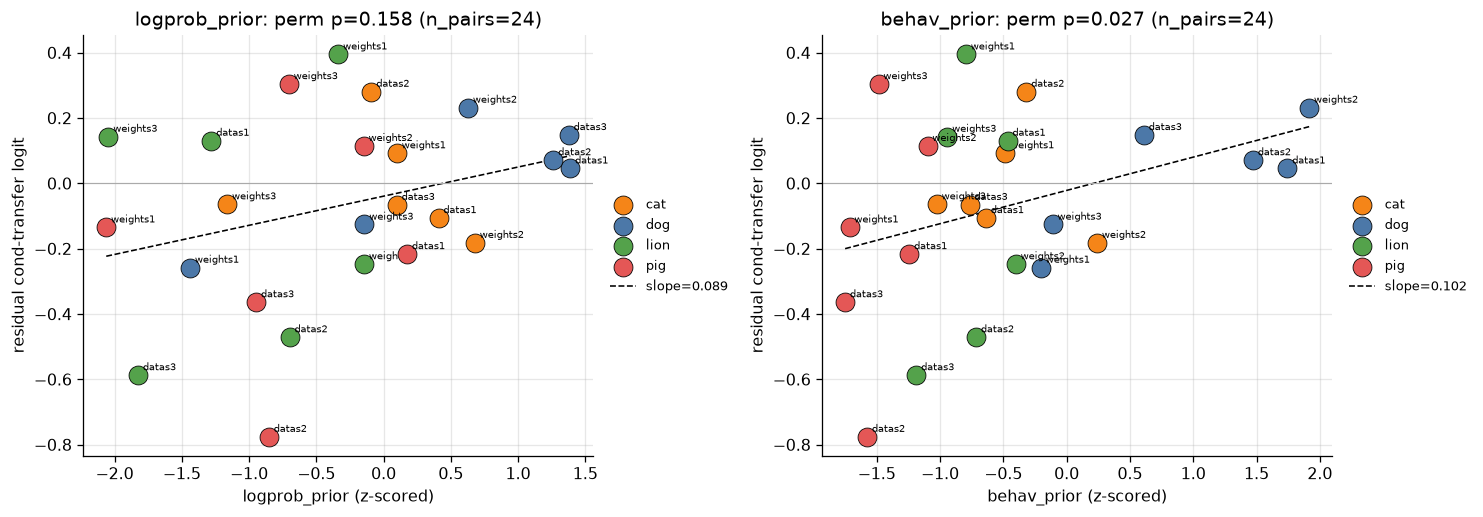

VERDICT [logprob_prior]: the student-base prior is NOT significant at the within-animal permutation test (slope=0.089, p=0.158); cluster-robust WLS β=0.146 (SE 0.059, p=0.0125, optimistic).
VERDICT [behav_prior]: the student-base prior is SIGNIFICANT at the within-animal permutation test (slope=0.102, p=0.027); cluster-robust WLS β=0.339 (SE 0.070, p=1.48e-06, optimistic).


In [8]:
import statsmodels.formula.api as smf

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, prior_col in zip(axes, ["logprob_prior", "behav_prior"]):
    key = (prior_col, "cond")
    if key not in perm_res:
        ax.text(0.5, 0.5, f"{prior_col}\narm not landed yet", ha="center", va="center")
        ax.axis("off"); continue
    df = tf._prep_fit_frame(cells, priors, prior_col, "cond")
    rm = smf.wls("y ~ C(animal) + C(base_label)", data=df, weights=df["w"]).fit()
    df = df.assign(_resid=rm.resid)
    agg = (df.groupby(["animal", "base_label"])
           .apply(lambda g: pd.Series({"resid": np.average(g["_resid"], weights=g["w"]),
                                        "prior_z": g["prior_z"].iloc[0]}), include_groups=False)
           .reset_index())
    for a in agg.animal.unique():
        s = agg[agg.animal == a]
        ax.scatter(s.prior_z, s.resid, s=140, color=ANIMAL_COLORS.get(a, "#888"),
                   label=a, edgecolor="k", linewidth=0.5, zorder=3)
        for _, r in s.iterrows():
            ax.annotate(r.base_label.replace("-seed", "s"), (r.prior_z, r.resid),
                        fontsize=6, xytext=(3, 3), textcoords="offset points")
    fit, perm = perm_res[key]
    xs = np.linspace(agg.prior_z.min(), agg.prior_z.max(), 20)
    ax.plot(xs, perm["obs_slope"] * (xs - agg.prior_z.mean()) + agg.resid.mean(),
            color="k", ls="--", lw=1, label=f"slope={perm['obs_slope']:.3f}")
    ax.axhline(0, color="#aaa", lw=0.7)
    ax.set_xlabel(f"{prior_col} (z-scored)"); ax.set_ylabel("residual cond-transfer logit")
    ax.set_title(f"{prior_col}: perm p={perm['p_two_sided']:.3f} (n_pairs={perm['n_pairs']})")
    aplots.right_legend(ax, anchor=(1.01, 0.5), fontsize=8)
plt.tight_layout(); plt.show()

for prior_col in ["logprob_prior", "behav_prior"]:
    key = (prior_col, "cond")
    if key not in perm_res:
        print(f"{prior_col}: not landed"); continue
    fit, perm = perm_res[key]
    sig = "SIGNIFICANT" if perm["p_two_sided"] < 0.05 else "NOT significant"
    print(f"VERDICT [{prior_col}]: the student-base prior is {sig} at the within-animal permutation "
          f"test (slope={perm['obs_slope']:.3f}, p={perm['p_two_sided']:.3f}); "
          f"cluster-robust WLS β={fit.beta:.3f} (SE {fit.se:.3f}, p={fit.p:.3g}, optimistic).")

## 6. Factor 1 — teacher imprint

**Row unit:** one teacher, within an animal. Per-teacher mean conditional transfer (averaged over
bases × cells) vs a teacher covariate: `teacher_p`, the teacher base's own trait score (favorite
`p_target` for pythia-160m). **Caveat:** `teacher_p` is seed-averaged over ft-seeds {0,1,2}, but
the campaign teachers are **tseed 1** specifically — so this is a proxy. Per-animal Pearson/Spearman
plus a pooled animal-FE fit.

Per-teacher cross-init transfer vs teacher_p (proxy; tseed-averaged). Row unit: teacher within animal; POOLED = animal-FE OLS partial.


,animal,r,rho,n,beta,p
0,cat,0.2916,0.1293,20,NaN,NaN
1,dog,0.0600,0.0135,20,NaN,NaN
2,lion,0.1883,-0.1879,10,NaN,NaN
3,pig,-0.0586,-0.0061,10,NaN,NaN
4,POOLED,0.1028,NaN,60,4.362,0.4466


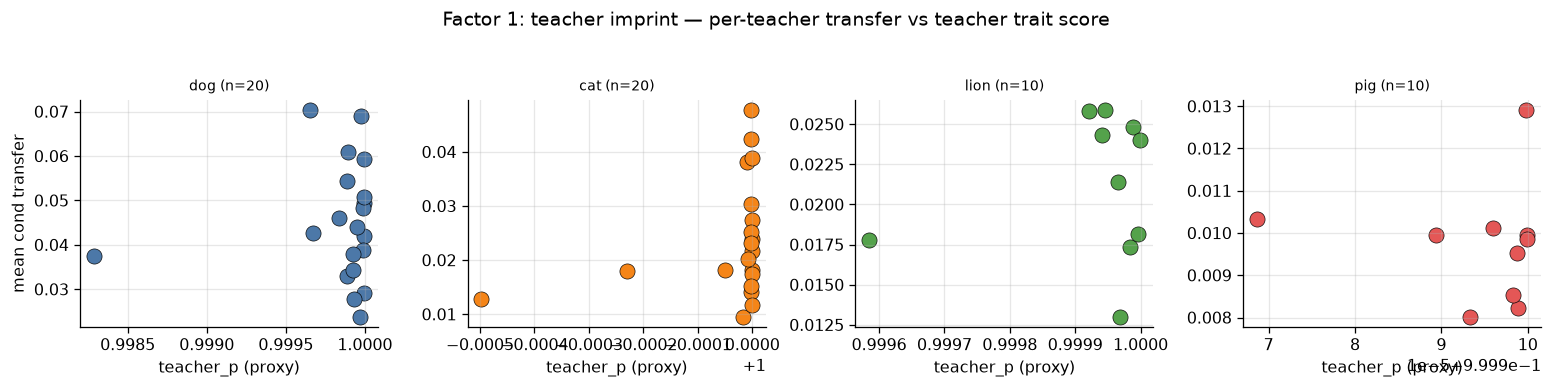

In [9]:
teacher_cov = tf.teacher_covariates(OUTPUT_ROOT, PARAM_TAGS)
f1 = tf.factor1_table(cells, teacher_cov)
print("Per-teacher cross-init transfer vs teacher_p (proxy; tseed-averaged). "
      "Row unit: teacher within animal; POOLED = animal-FE OLS partial.")
display(f1.round(4))

per_teacher = (cells[cells["cond"].notna()]
               .groupby(["animal", "teacher_tag"])["cond"].mean().reset_index()
               .merge(teacher_cov, on=["animal", "teacher_tag"], how="left"))
landed = [a for a in tf.FOCUS_ANIMALS if (per_teacher.animal == a).any()]
fig, axes = plt.subplots(1, len(landed), figsize=(3.4 * len(landed), 3.2), squeeze=False)
for ax, a in zip(axes[0], landed):
    s = per_teacher[per_teacher.animal == a]
    ax.scatter(s.teacher_p, s.cond, s=90, color=ANIMAL_COLORS.get(a, "#888"),
               edgecolor="k", linewidth=0.4)
    ax.set_title(f"{a} (n={len(s)})", fontsize=9)
    ax.set_xlabel("teacher_p (proxy)")
axes[0][0].set_ylabel("mean cond transfer")
fig.suptitle("Factor 1: teacher imprint — per-teacher transfer vs teacher trait score", y=1.04)
plt.tight_layout(); plt.show()

## 7. ds vs ws residual structure — factors 4 & 5

**Row unit:** one student base. Fitted base fixed effects (centered), from the conditional-transfer
logit regression, **with and without** the prior term. CIs are a teacher-clustered bootstrap
(1000 resamples, fixed seed). Group means for data-seed vs weight-seed bases. **Honest caveat:**
only 2–3 bases per group at current coverage — group means are suggestive, not conclusive.

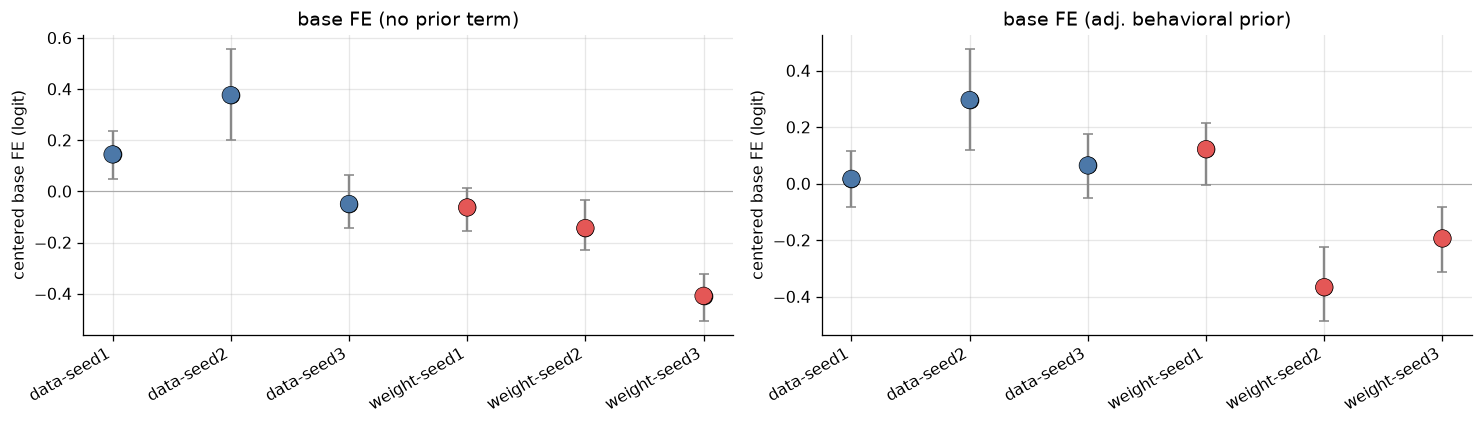

[no prior] ds mean FE=+0.157 (n=3 bases), ws mean FE=-0.205 (n=3 bases), ds-ws gap=+0.362
[prior-adjusted] ds mean FE=+0.126 (n=3 bases), ws mean FE=-0.146 (n=3 bases), ds-ws gap=+0.272


In [10]:
be_noprior = tf.base_effects(cells, n_boot=1000, seed=0)
be_prior = tf.base_effects(cells, priors=priors, prior_col="behav_prior", n_boot=1000, seed=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, be, title in [(axes[0], be_noprior, "base FE (no prior term)"),
                      (axes[1], be_prior, "base FE (adj. behavioral prior)")]:
    be = be.sort_values("base_label").reset_index(drop=True)
    colors = ["#4c78a8" if g == "ds" else "#e45756" for g in be.group]
    ax.errorbar(range(len(be)), be.fe, yerr=[be.fe - be.ci_lo, be.ci_hi - be.fe],
                fmt="o", ms=10, color="k", ecolor="#888", capsize=3, zorder=3)
    ax.scatter(range(len(be)), be.fe, s=120, c=colors, zorder=4, edgecolor="k", linewidth=0.4)
    ax.set_xticks(range(len(be))); ax.set_xticklabels(be.base_label, rotation=30, ha="right")
    ax.axhline(0, color="#aaa", lw=0.7); ax.set_ylabel("centered base FE (logit)")
    ax.set_title(title)
plt.tight_layout(); plt.show()

for name, be in [("no prior", be_noprior), ("prior-adjusted", be_prior)]:
    g = be.groupby("group").fe.agg(["mean", "count"])
    ds = g.loc["ds", "mean"] if "ds" in g.index else float("nan")
    ws = g.loc["ws", "mean"] if "ws" in g.index else float("nan")
    nds = int(g.loc["ds", "count"]) if "ds" in g.index else 0
    nws = int(g.loc["ws", "count"]) if "ws" in g.index else 0
    print(f"[{name}] ds mean FE={ds:+.3f} (n={nds} bases), ws mean FE={ws:+.3f} (n={nws} bases), "
          f"ds-ws gap={ds - ws:+.3f}")

## 8. Shared-core slice views — unconditional transfer by model, animal, and teacher

Descriptive slices of the one design that is complete on **all 24 animal×base arms**, using a
readout that needs **no collapse threshold** (per the calibration caution — the dead label is
not trusted for inference yet, so nothing here conditions on it).

**Construction (selection, fixed for every table in this section):**

- **Teachers:** the **top-10** subset `PARAM_TAGS[:10]` (= `run_logs/dog_top10_kband_configs.json`,
  same ranked list for every animal). The full 20-teacher set landed only on dog/cat ds1/ws1, so
  slicing on all 20 would compare 20-teacher arms against 10-teacher arms.
- **Student cells:** the 20 focus cells; **student seed 1 only** (the campaign seed — drops stray
  multi-seed runs that older campaigns left at overlapping cells).
- **Readout:** `ratio = test / test_prior`, the *unconditional* transfer ratio in probability
  space. `test` = mean p(target animal) over the 50 held-out test prompts; `test_prior` = that
  (animal, base)'s own untrained score **on the same prompt set** (like-for-like, not
  `behav_prior` which is measured on the favorite/train prompts). ratio = 1 ⇒ no transfer;
  a collapsed seed contributes ≈ 0 rather than being excluded, so collapse and magnitude are
  integrated in one number: E[ratio] = P(alive)·E[ratio | alive].
- **Pairing (Δ views):** a pair is an identical (teacher config, student cell) with
  `data-seed-i` matched to `weight-seed-i`, i ∈ {1,2,3}. The i-pairing is a *labeling
  convention* — ds2 and ws2 are unrelated seed draws; it only serves to form matched pairs.

Per the per-model-first house convention, the **by-model table (8a) is the primary view**; the
animal×group pool (8b) is a 3-arm aggregate whose ds/ws contrast is carried by individual arms,
and the teacher slice (8c) is the within-group sign-consistency check. All numbers are
descriptive medians/means — inference on the ds/ws structure is §5's permutation test, never
these pooled rows.

8a. BY MODEL: unconditional test/test_prior ratio (row = arm; median/mean over ~200 teacher x cell runs, seed 1)
animal         cat               dog              lion               pig            
              mean median    n  mean median    n  mean median    n  mean median    n
base_label                                                                          
data-seed1    3.48   2.18  200  4.24   2.95  199  4.55   3.11  200  1.72   1.07  200
data-seed2    8.57   4.35  200  6.66   5.21  200  4.73   2.66  200  0.64   0.41  200
data-seed3    3.06   2.27  200  5.35   3.77  200  1.23   0.75  200  0.98   0.77  200
weight-seed1  3.68   1.83  200  3.46   2.29  200  7.00   4.66  200  1.59   1.04  200
weight-seed2  1.44   1.23  200  2.92   2.17  200  1.99   1.64  200  1.64   1.07  200
weight-seed3  2.23   1.71  196  3.59   2.82  200  3.22   2.23  200  1.28   0.50  200


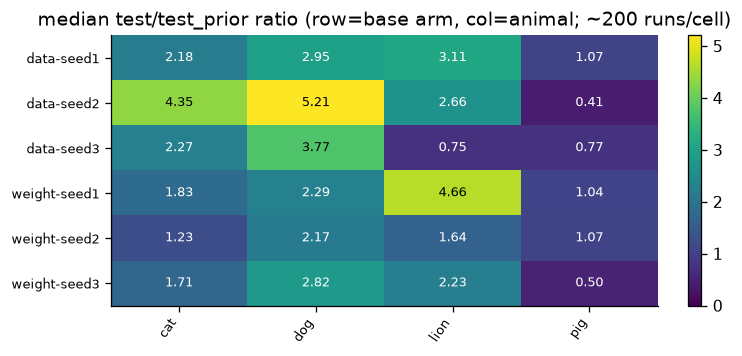

In [11]:
# --- §8 shared frame: top-10 teachers x focus-20 cells x seed 1, unconditional test/prior ratio
TOP10 = PARAM_TAGS[:10]
core = runs[(runs["seed"] == 1) & (runs["teacher_tag"].isin(TOP10))].copy()
tp = priors.set_index(["animal", "base_label"])["test_prior"]
core["test_prior"] = tp.reindex(pd.MultiIndex.from_frame(core[["animal", "base_label"]])).to_numpy()
assert core["test_prior"].notna().all(), "missing test_prior for a landed (animal, base)"
core["ratio"] = core["test"] / core["test_prior"]
core["grp"] = np.where(core["base_label"].str.startswith("data"), "ds", "ws")
core["sidx"] = core["base_label"].str.extract(r"(\d)").astype(int)

# 8a. BY MODEL -- row = one animal x student-base arm; aggregation = median/mean of ratio over
# the 10 teachers x 20 cells (~200 seed-1 runs) landed on that arm.
bymodel = (core.groupby(["animal", "base_label"])["ratio"]
           .agg(n="size", median="median", mean="mean").round(2))
print("8a. BY MODEL: unconditional test/test_prior ratio "
      "(row = arm; median/mean over ~200 teacher x cell runs, seed 1)")
print(bymodel.unstack("animal").swaplevel(axis=1).sort_index(axis=1).to_string())

med = bymodel["median"].unstack("animal")
med = med.reindex([b for b in tf.FOCUS_BASE_LABELS if b in med.index])
fig, ax = plt.subplots(figsize=(6.5, 3.2))
im = aplots.annotated_heatmap(ax, med, cmap="viridis", vmin=0, vmax=np.nanmax(med.values),
                              fmt="{:.2f}", origin="upper", mid=0.6 * np.nanmax(med.values),
                              cell_fontsize=8)
ax.set_title("median test/test_prior ratio (row=base arm, col=animal; ~200 runs/cell)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

In [12]:
# 8b. BY ANIMAL x GROUP -- pools the 3 arms per group (~600 runs per side). A summary of 8a's
# heterogeneous rows, NOT an independent result: e.g. lion's ws pool rides on the ws1 arm and
# cat's ds pool on the ds2 arm. n=3 bases per group.
bygrp = (core.groupby(["animal", "grp"])["ratio"]
         .agg(n="size", median="median", mean="mean").round(2))
print("8b. BY ANIMAL x GROUP (pool of 3 arms x 10 teachers x 20 cells; see 8a for the per-arm view)")
print(bygrp.unstack("grp").to_string())

# paired unconditional contrast: identical (teacher, cell), ds_i vs ws_i, dead seeds included
pv = core.pivot_table(index=["animal", "teacher_tag", "student_tag", "sidx"],
                      columns="grp", values="ratio").dropna()
d = pv["ds"] - pv["ws"]
paired = pd.DataFrame({
    "n_pairs": d.groupby(level=0).size(),
    "median_delta": d.groupby(level=0).median().round(2),
    "ds_wins": d.groupby(level=0).apply(lambda s: (s > 0).mean()).round(3),
})
print("\npaired Delta ratio (ds - ws) on matched (teacher, cell, seed-index) triples, "
      "all pairs incl. collapsed seeds:")
print(paired.to_string())

8b. BY ANIMAL x GROUP (pool of 3 arms x 10 teachers x 20 cells; see 8a for the per-arm view)
          n      median        mean      
grp      ds   ws     ds    ws    ds    ws
animal                                   
cat     600  596   2.76  1.53  5.04  2.46
dog     599  600   3.82  2.37  5.42  3.32
lion    600  600   1.82  2.55  3.50  4.07
pig     600  600   0.70  0.89  1.11  1.50

paired Delta ratio (ds - ws) on matched (teacher, cell, seed-index) triples, all pairs incl. collapsed seeds:
        n_pairs  median_delta  ds_wins
animal                                
cat         596          1.23    0.676
dog         599          1.13    0.634
lion        600         -0.45    0.418
pig         600         -0.15    0.423


In [13]:
# 8c. BY TEACHER -- sign-consistency check within each animal. Row = teacher (manifest rank
# order); value = median ratio over that teacher's 3 arms x 20 cells (~60 runs) per side,
# plus the median paired Delta (ds - ws) per teacher.
byt = (core.groupby(["teacher_tag", "animal", "grp"])["ratio"].median()
       .unstack(["animal", "grp"]).sort_index(axis=1).reindex(TOP10).round(2))
print("8c. BY TEACHER: median ratio per (teacher, animal, side); ~60 runs per entry")
print(byt.to_string())

dt = (pv["ds"] - pv["ws"]).groupby(level=[0, 1]).median().unstack(0).reindex(TOP10).round(2)
print("\nper-teacher median paired Delta ratio (ds - ws); positive = ds-advantage:")
print(dt.to_string())
sign = (dt > 0).sum()
print("\nteachers with ds-advantage (of 10):", dict(sign))

8c. BY TEACHER: median ratio per (teacher, animal, side); ~60 runs per entry
animal               cat         dog        lion         pig      
grp                   ds    ws    ds    ws    ds    ws    ds    ws
teacher_tag                                                       
ep20_lr1e-4_r16a32  2.04  1.89  3.96  2.78  1.62  2.55  1.03  1.38
ep2_lr5e-4_r32a64   2.93  1.36  8.76  3.55  1.31  1.57  0.78  1.12
ep7_lr5e-4_r8a8     4.43  1.63  5.29  3.09  1.89  3.01  0.95  0.83
ep10_lr1e-4_r64a64  2.21  1.37  4.55  2.05  3.27  2.20  0.99  0.77
ep20_lr1e-4_r8a16   1.59  1.36  2.62  1.75  1.16  1.87  0.48  0.65
ep5_lr5e-4_r8a16    3.80  1.36  3.95  2.71  2.83  2.28  0.82  0.70
ep5_lr2e-4_r64a64   5.02  2.63  3.83  1.93  2.84  3.76  0.51  1.19
ep7_lr2e-4_r32a32   4.04  1.90  2.68  2.47  1.86  2.75  0.59  0.96
ep10_lr1e-4_r32a64  2.64  0.80  3.47  3.08  1.65  3.35  0.75  1.20
ep7_lr1e-4_r32a64   2.48  1.76  1.76  1.46  1.49  1.53  0.50  0.66

per-teacher median paired Delta ratio (ds - ws); po

## 9. Same-model teacher quality — and does it predict cross-init transfer?

Two questions: (a) do same-model distillation scores agree *across animals* — are some teachers
generally good? (b) does a teacher's same-model score predict its *cross-init* transfer?

**Same-model** = each teacher distilled back into its **own** base (pythia-160m), std recipe
(`ep{e}_lr1e-4_r8a32`, lr 1e-4, r8/α32), **single ftseed**. The dataset pool is n100k for
dog/lion/pig and **n40k for cat** (discovered by glob; n100k preferred where both exist). The
common cross-animal cell is **ep10** (ep20 exists for dog only), so §9a/§9b use ep10.

### 9a. The (teacher × animal) same-model table and cross-animal rank agreement — ALL teachers

**Row unit:** one teacher. We now use **every** same-model lineage on disk (not just the focus-20),
so the cross-animal rank agreement is read over the full quality range — the focus-20 are dog's
*top* teachers, so restricting to them truncates the range and deflates the correlation.

- **Left heatmap:** same-model `sm_p` per animal at the ep10 std cell, rows sorted by cross-animal
  mean rank (rank 1 = highest sm_p). With many shared teachers we show the **top-20 and bottom-20**
  by mean rank and say so.
- **Right heatmap:** the 4×4 cross-animal **Spearman** rank-correlation of `sm_p`, pairwise-complete
  over shared teachers, annotated with ρ and pairwise **n**.

**Caveat:** cat's same-model pool is n40k, and cat's *cross-init* runs used the REGENERATED n100k
pools — different data, so cat's same-model↔cross-init link (§9b) is the loosest.

same-model lineages found per animal (ep10 std cell), ALL teachers:
  dog  : 102 teachers  (pool ex10-20_prefix_n100k)
  cat  :  84 teachers  (pool ex10-20_prefix_n40k)
  lion :  96 teachers  (pool ex10-20_prefix_n100k)
  pig  :  96 teachers  (pool ex10-20_prefix_n100k)

84 teachers are present in all 4 animals (fully shared).


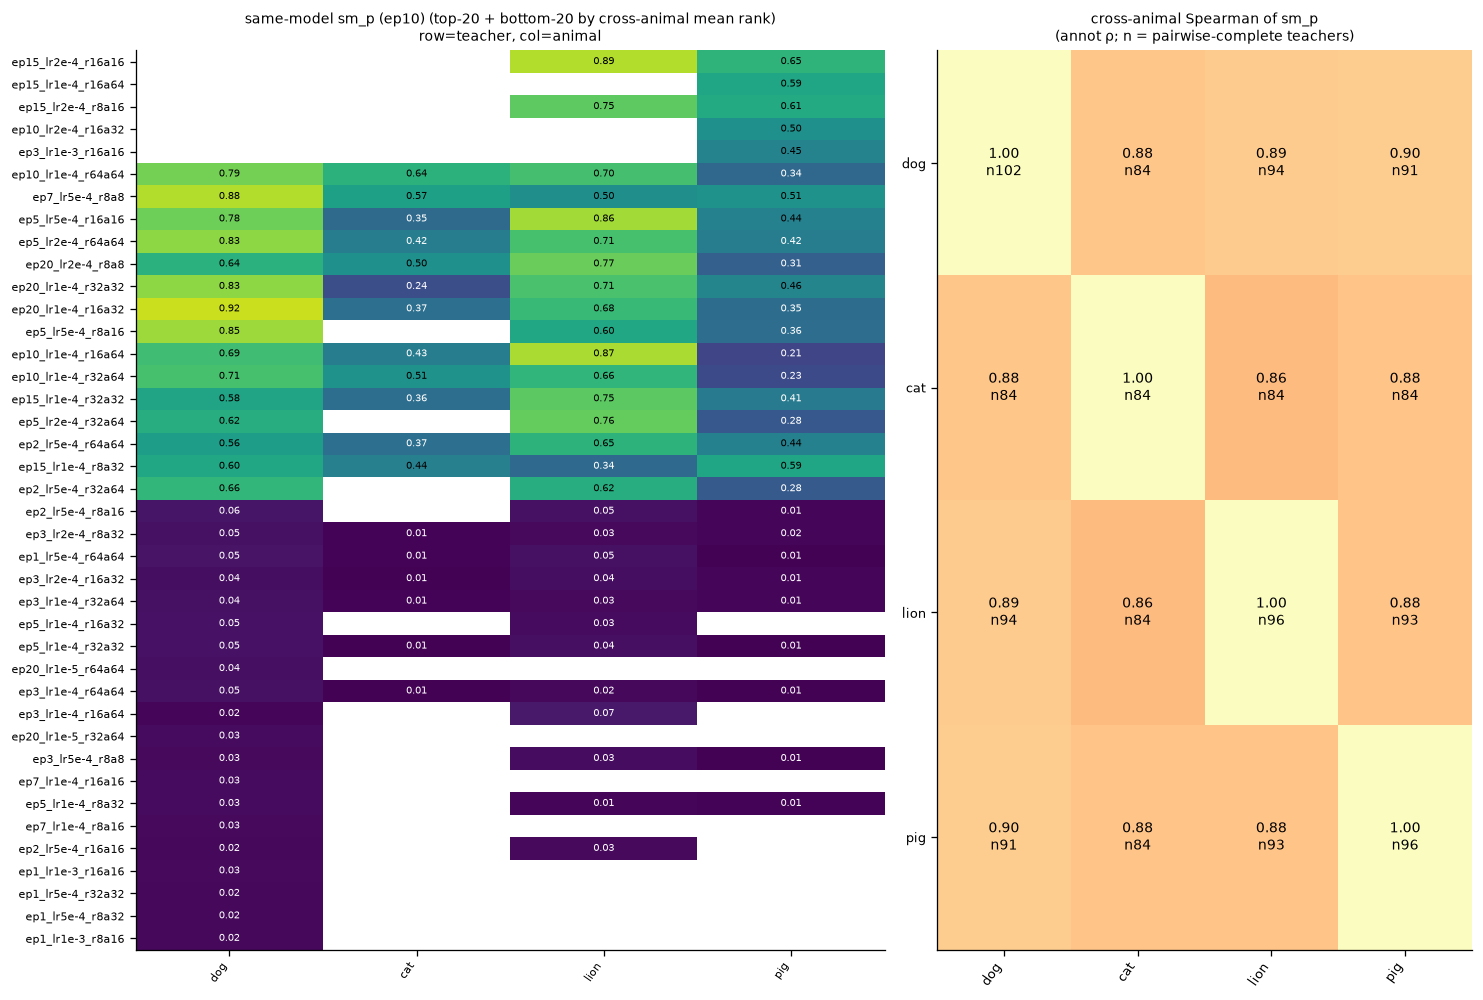

Cross-animal Spearman matrix (ALL teachers):


,dog,cat,lion,pig
dog,1.000,0.880,0.894,0.897
cat,0.880,1.000,0.859,0.876
lion,0.894,0.859,1.000,0.878
pig,0.897,0.876,0.878,1.000


Pairwise-complete teacher counts:


,dog,cat,lion,pig
dog,102,84,94,91
cat,84,84,84,84
lion,94,84,96,93
pig,91,84,93,96


In [14]:
SM_LADDER = tuple(f"ep{e}_lr1e-4_r8a32" for e in (1, 2, 5, 10, 20))
SM_CELL = "ep10_lr1e-4_r8a32"  # common across all four animals (ep20 is dog-only)
# param_tags=None -> discover EVERY same-model lineage on disk (drops the focus-20 restriction).
sm_all = tf.same_model_scores(OUTPUT_ROOT, None, student_cells=(SM_CELL,))
print("same-model lineages found per animal (ep10 std cell), ALL teachers:")
for a in tf.FOCUS_ANIMALS:
    sub = sm_all[sm_all.animal == a]
    ds = sub['dataset'].iloc[0] if len(sub) else '-'
    print(f"  {a:5s}: {len(sub):3d} teachers  (pool {ds})")

mat, gtab, nmat = tf.teacher_generality(sm_all, SM_CELL)
animals_g = list(mat.index)
n_all4 = int((gtab["n_animals"] == len(animals_g)).sum())
print(f"\n{n_all4} teachers are present in all {len(animals_g)} animals (fully shared).")

# Row-subset the sm_p heatmap when there are too many teachers to read.
sm_wide = gtab[animals_g]
note = ""
if len(sm_wide) > 40:
    sm_show = pd.concat([sm_wide.head(20), sm_wide.tail(20)])
    note = " (top-20 + bottom-20 by cross-animal mean rank)"
else:
    sm_show = sm_wide

fig, axes = plt.subplots(1, 2, figsize=(13, max(5, 0.22 * len(sm_show))),
                         gridspec_kw={"width_ratios": [1.4, 1]})
aplots.annotated_heatmap(axes[0], sm_show, cmap="viridis", vmin=0.0, vmax=1.0,
                         fmt="{:.2f}", origin="upper", cell_fontsize=6, tick_fontsize=7)
axes[0].set_title(f"same-model sm_p (ep10){note}\nrow=teacher, col=animal", fontsize=9)
aplots.annotated_heatmap(axes[1], mat, cmap="magma", vmin=0.0, vmax=1.0, counts=nmat.astype(int),
                         fmt="{:.2f}", origin="upper", cell_fontsize=9)
axes[1].set_title("cross-animal Spearman of sm_p\n(annot ρ; n = pairwise-complete teachers)",
                  fontsize=9)
plt.tight_layout(); plt.show()

print("Cross-animal Spearman matrix (ALL teachers):"); display(mat.round(3))
print("Pairwise-complete teacher counts:"); display(nmat.astype(int))

### 9b. Does same-model score predict cross-init transfer?

Two aggregations, stated explicitly:

- **Pooled scatter (below):** **row unit = one teacher within an animal.** x = same-model `sm_p`
  (ep10); y = that teacher's cross-init **conditional transfer**, **pooled = the mean over the
  landed student bases × the focus cells, every cell weighted equally**. Per-panel Pearson r /
  Spearman ρ / n; pooled within-animal partial r + p printed (survival response as a table).
- **Per-(animal × base) table (§9b-ii):** the same correlation computed **within each landed
  (animal, base) arm** separately, so a strong base does not mask a weak one.

The focus-20 teachers are used here (only they have cross-init runs).

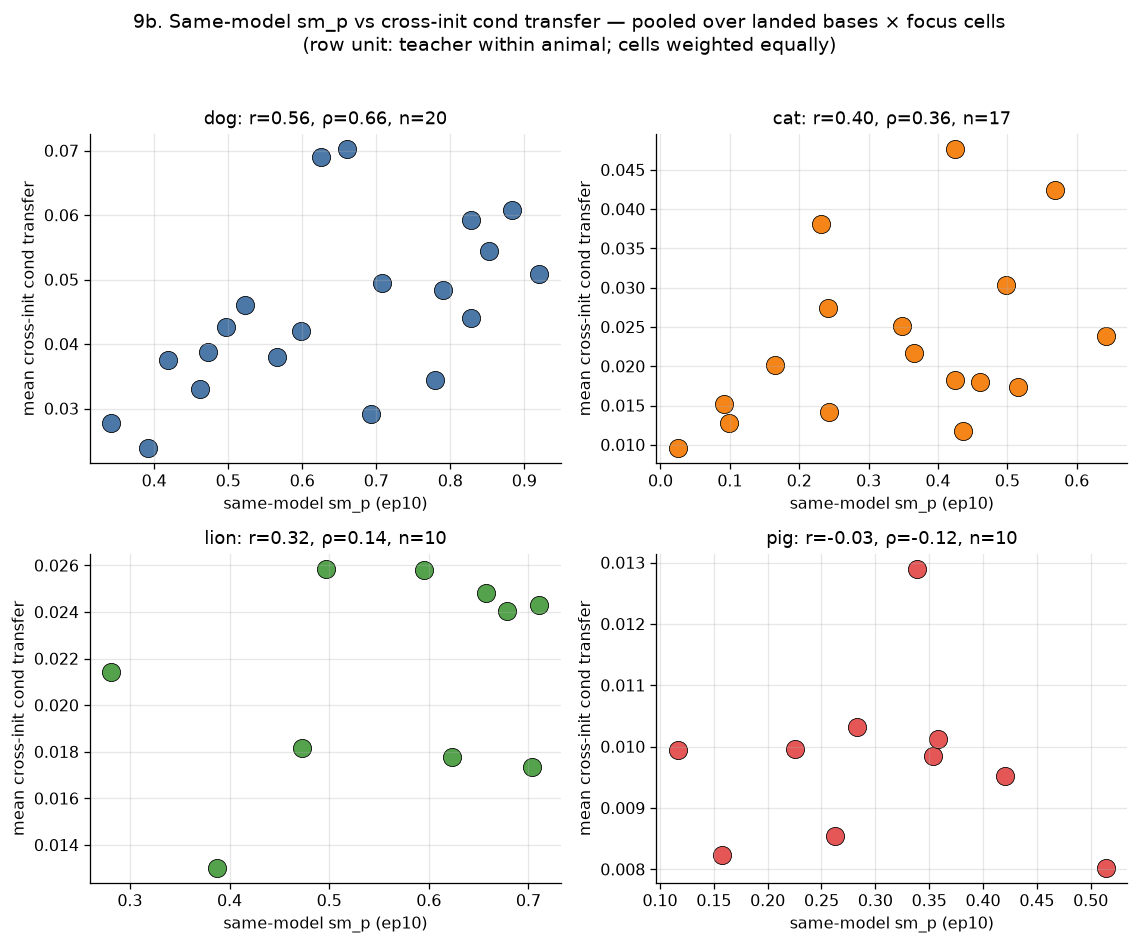

Conditional-transfer response — per-animal + POOLED within-animal partial r:


,animal,r,rho,n,beta,p
0,cat,0.4041,0.3627,17,NaN,NaN
1,dog,0.5574,0.6556,20,NaN,NaN
2,lion,0.3221,0.1394,10,NaN,NaN
3,pig,-0.0309,-0.1152,10,NaN,NaN
4,POOLED,0.4463,NaN,57,0.0272,0.0007


Survival response — per-animal + POOLED within-animal partial r:


,animal,r,rho,n,beta,p
0,cat,0.3171,0.1247,17,NaN,NaN
1,dog,0.6106,0.6167,20,NaN,NaN
2,lion,0.2366,0.4329,10,NaN,NaN
3,pig,0.3780,0.3587,10,NaN,NaN
4,POOLED,0.3783,NaN,57,0.1955,0.0048


POOLED (cond): partial r=0.446, β=0.0272, p=0.0007
POOLED (surv): partial r=0.378, β=0.1955, p=0.0048

partial r = Pearson correlation of the two variables after removing each animal's mean (both residualized on animal FEs); i.e. the within-animal association, immune to cross-animal level differences.


In [15]:
cov_sm = tf.teacher_covariates(OUTPUT_ROOT, PARAM_TAGS, samemodel_cell=SM_CELL)
f1_sm_cond = tf.factor1_table(cells, cov_sm, covariate="samemodel_p", response="cond")
f1_sm_surv = tf.factor1_table(cells, cov_sm, covariate="samemodel_p", response="surv")

pt = (cells[cells["cond"].notna()].groupby(["animal", "teacher_tag"])["cond"].mean().reset_index()
      .merge(cov_sm[["animal", "teacher_tag", "samemodel_p"]], on=["animal", "teacher_tag"])
      .dropna(subset=["cond", "samemodel_p"]))
landed = [a for a in tf.FOCUS_ANIMALS if (pt.animal == a).any()]
r_by = {row.animal: (row.r, row.rho, int(row.n)) for row in f1_sm_cond.itertuples() if row.animal != "POOLED"}
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, a in zip(axes.ravel(), landed):
    s = pt[pt.animal == a]
    ax.scatter(s.samemodel_p, s.cond, s=130, color=ANIMAL_COLORS.get(a, "#888"),
               edgecolor="k", linewidth=0.5)
    r, rho, n = r_by.get(a, (np.nan, np.nan, len(s)))
    ax.set_title(f"{a}: r={r:.2f}, ρ={rho:.2f}, n={n}", fontsize=11)
    ax.set_xlabel("same-model sm_p (ep10)"); ax.set_ylabel("mean cross-init cond transfer")
for ax in axes.ravel()[len(landed):]:
    ax.axis("off")
fig.suptitle("9b. Same-model sm_p vs cross-init cond transfer — pooled over landed bases × focus "
             "cells\n(row unit: teacher within animal; cells weighted equally)", y=1.02)
plt.tight_layout(); plt.show()

print("Conditional-transfer response — per-animal + POOLED within-animal partial r:")
display(f1_sm_cond.round(4))
print("Survival response — per-animal + POOLED within-animal partial r:")
display(f1_sm_surv.round(4))
pc = f1_sm_cond.set_index("animal").loc["POOLED"]
ps = f1_sm_surv.set_index("animal").loc["POOLED"]
print(f"POOLED (cond): partial r={pc['r']:.3f}, β={pc.get('beta', float('nan')):.4f}, "
      f"p={pc.get('p', float('nan')):.4f}")
print(f"POOLED (surv): partial r={ps['r']:.3f}, β={ps.get('beta', float('nan')):.4f}, "
      f"p={ps.get('p', float('nan')):.4f}")
print("\npartial r = Pearson correlation of the two variables after removing each animal's mean "
      "(both residualized on animal FEs); i.e. the within-animal association, immune to "
      "cross-animal level differences.")

#### 9b-ii. Same-model↔cross-init correlation *within each (animal × base) arm*

**Row unit of each correlation:** one teacher. Within each landed (animal, base) arm we correlate
teacher `sm_p` (ep10) against that teacher's mean cross-init `cond` over the focus cells in **that
base only**, reporting Pearson r, Spearman ρ, and n teachers. This unpools the §9b scatter so a
base with many surviving teachers cannot mask one with few. Cells annotate ρ with n.

Per-(animal × base) same-model↔cross-init correlation (row unit: teacher within that arm):


,animal,base_label,r,rho,n
0,cat,data-seed1,0.252,0.463,17
1,cat,data-seed2,0.298,0.214,8
2,cat,data-seed3,0.142,-0.048,8
3,cat,weight-seed1,0.361,0.199,17
4,cat,weight-seed2,-0.007,-0.167,8
5,cat,weight-seed3,0.329,0.095,8
6,dog,data-seed1,0.329,0.353,20
7,dog,data-seed2,0.563,0.539,10
8,dog,data-seed3,0.577,0.382,10
9,dog,weight-seed1,0.363,0.426,20


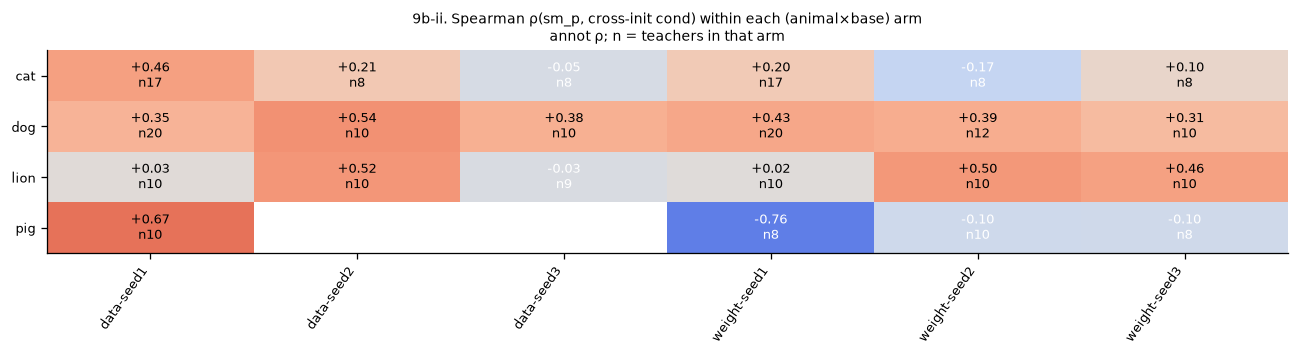

In [16]:
cond_bt = (cells[cells["cond"].notna()]
           .groupby(["animal", "base_label", "teacher_tag"])["cond"].mean().reset_index()
           .merge(cov_sm[["animal", "teacher_tag", "samemodel_p"]], on=["animal", "teacher_tag"])
           .dropna(subset=["cond", "samemodel_p"]))
from scipy.stats import pearsonr, spearmanr
rows_ab = []
for (a, b), g in cond_bt.groupby(["animal", "base_label"]):
    n = len(g)
    if n >= 3 and g.samemodel_p.nunique() > 1 and g.cond.nunique() > 1:
        r = float(pearsonr(g.samemodel_p, g.cond)[0]); rho = float(spearmanr(g.samemodel_p, g.cond)[0])
    else:
        r = rho = np.nan
    rows_ab.append({"animal": a, "base_label": b, "r": round(r, 3), "rho": round(rho, 3), "n": n})
ab_tab = pd.DataFrame(rows_ab).sort_values(["animal", "base_label"]).reset_index(drop=True)
print("Per-(animal × base) same-model↔cross-init correlation (row unit: teacher within that arm):")
display(ab_tab)

rho_grid = ab_tab.pivot(index="animal", columns="base_label", values="rho")
n_grid = ab_tab.pivot(index="animal", columns="base_label", values="n")
cols_o = [c for c in tf.FOCUS_BASE_LABELS if c in rho_grid.columns]
rho_grid, n_grid = rho_grid[cols_o], n_grid[cols_o]
fig, ax = plt.subplots(figsize=(1.4 * len(cols_o) + 3, 3.2))
aplots.annotated_heatmap(ax, rho_grid, cmap="coolwarm", vmin=-1.0, vmax=1.0, mid=0.0,
                         counts=n_grid.fillna(0).astype(int), fmt="{:+.2f}", origin="upper",
                         cell_fontsize=8)
ax.set_title("9b-ii. Spearman ρ(sm_p, cross-init cond) within each (animal×base) arm\n"
             "annot ρ; n = teachers in that arm", fontsize=9)
plt.tight_layout(); plt.show()

#### 9b-iii. Is the teacher strength order the same across student bases?

**Question:** does a teacher that transfers well into ds1 also transfer well into ws2? For each
animal with ≥2 landed bases we build the **base × base Spearman matrix** of per-teacher mean
cross-init `cond` (pairwise-complete teachers, n annotated). Then a **pooled** version whose unit
is the (animal, teacher) pair, so it reads the base-to-base order agreement across all animals at
once. Animals with <2 landed bases are skipped (stated).

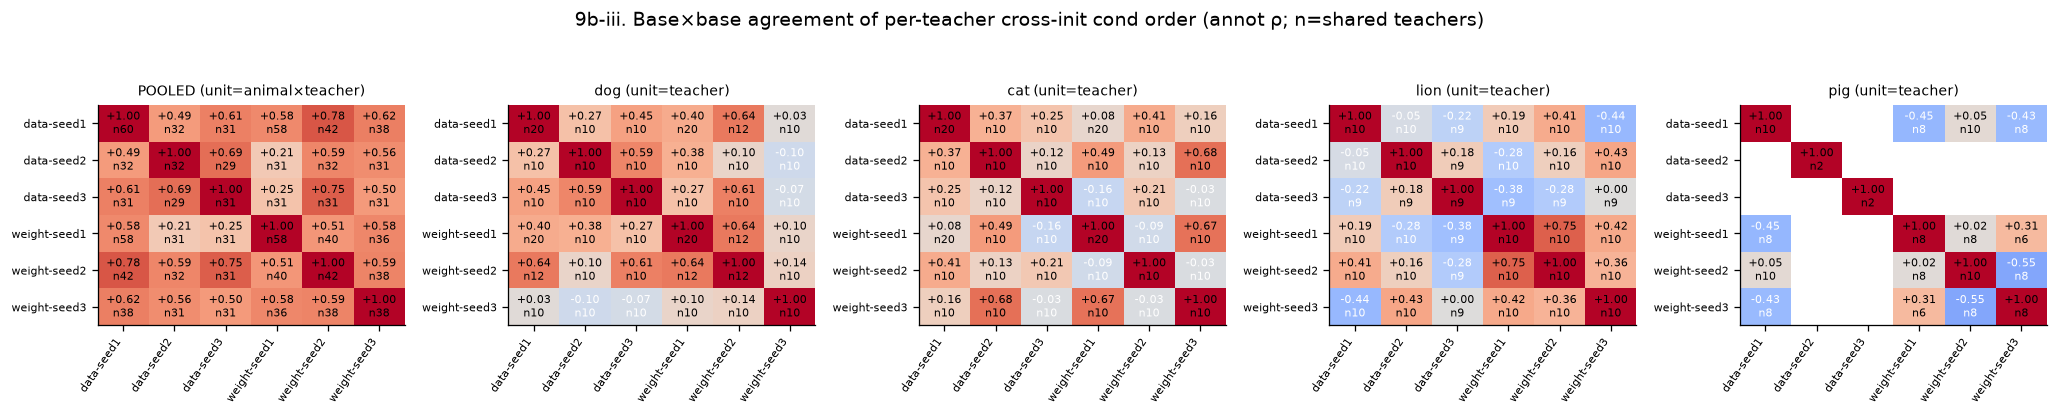

POOLED base×base Spearman ρ:


,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
data-seed1,1.000,0.487,0.610,0.576,0.783,0.617
data-seed2,0.487,1.000,0.693,0.206,0.587,0.556
data-seed3,0.610,0.693,1.000,0.254,0.755,0.496
weight-seed1,0.576,0.206,0.254,1.000,0.511,0.585
weight-seed2,0.783,0.587,0.755,0.511,1.000,0.595
weight-seed3,0.617,0.556,0.496,0.585,0.595,1.000


POOLED pairwise n (shared animal×teacher units):


,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
data-seed1,60,32,31,58,42,38
data-seed2,32,32,29,31,32,31
data-seed3,31,29,31,31,31,31
weight-seed1,58,31,31,58,40,36
weight-seed2,42,32,31,40,42,38
weight-seed3,38,31,31,36,38,38


In [17]:
# Pooled across animals: unit = (animal, teacher), matrix over bases.
rho_pool, n_pool = tf.teacher_order_agreement(cells, by="base_label", value="cond",
                                              unit=("animal", "teacher_tag"))
cols_p = [c for c in tf.FOCUS_BASE_LABELS if c in rho_pool.columns]
rho_pool, n_pool = rho_pool.loc[cols_p, cols_p], n_pool.loc[cols_p, cols_p]

by_animal = {}
for a in tf.FOCUS_ANIMALS:
    ca = cells[cells.animal == a]
    nb = ca.dropna(subset=["cond"])["base_label"].nunique()
    if nb >= 2:
        rho_a, n_a = tf.teacher_order_agreement(ca, by="base_label", value="cond", unit=("teacher_tag",))
        cols_a = [c for c in tf.FOCUS_BASE_LABELS if c in rho_a.columns]
        by_animal[a] = (rho_a.loc[cols_a, cols_a], n_a.loc[cols_a, cols_a])
    else:
        print(f"  {a}: only {nb} landed base(s) — skipped (need >=2)")

panels = [("POOLED (unit=animal×teacher)", rho_pool, n_pool)] + \
         [(f"{a} (unit=teacher)", r, n) for a, (r, n) in by_animal.items()]
fig, axes = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 3.4), squeeze=False)
for ax, (title, r, n) in zip(axes[0], panels):
    aplots.annotated_heatmap(ax, r, cmap="coolwarm", vmin=-1.0, vmax=1.0, mid=0.0,
                             counts=n.fillna(0).astype(int), fmt="{:+.2f}", origin="upper",
                             cell_fontsize=7, tick_fontsize=7)
    ax.set_title(title, fontsize=9)
fig.suptitle("9b-iii. Base×base agreement of per-teacher cross-init cond order (annot ρ; n=shared teachers)",
             y=1.05)
plt.tight_layout(); plt.show()
print("POOLED base×base Spearman ρ:"); display(rho_pool.round(3))
print("POOLED pairwise n (shared animal×teacher units):"); display(n_pool.astype(int))

> **SELECTION CAVEAT (read before interpreting 9b).** The 20 teachers *are* dog's top-20 by
> exactly this screen (single-ftseed, same-model **ep20**). So the **dog** panel is
> **range-restricted** — only the top of dog's ranking is present — and its same-model↔cross-init
> correlation is **attenuated** by construction. cat / lion / pig scores played **no role** in
> selecting these teachers, so those panels are the **clean read** of whether same-model quality
> predicts cross-init transfer.

## 10. Interpretation — what can and cannot be concluded now

- **Coverage is partial.** Several arms (weight-seed3, data-seed3 for most animals; lion/pig
  beyond ds1/ws1) are thin or absent, so the within-animal cross-base contrast rests on ~15
  (animal × base) points. The permutation test is the honest inference at this n.
- **The prior verdict** printed in §5 is the headline: whether the measured student-base prior
  (logprob and behavioral) explains within-animal cross-base transfer, net of animal and base
  fixed effects. Read the permutation p, not the cluster-robust p.
- **Factor 1** (teacher imprint) uses a tseed-averaged proxy for the tseed-1 campaign teachers;
  treat per-animal correlations as indicative.
- **Same-model quality (§9)** partially predicts cross-init conditional transfer — the pooled
  within-animal partial r is positive and significant — but the effect is carried by cat/dog while
  lion/pig are near-null, and dog is range-restricted by the selection screen, so this is a
  qualified "yes, weakly" rather than a clean law. Across the FULL teacher range (§9a) same-model
  quality agrees strongly cross-animal (ρ≈0.86–0.90); the focus-20 truncation to dog's top slice
  is what deflated it.
- **Teacher order across bases (§9b-iii)** is positively but only moderately correlated
  (pooled base×base ρ mostly 0.3–0.8) — the teacher that transfers best is somewhat, not fully,
  base-invariant.
- **ds-vs-ws** rests on 2–3 bases per group — a group-mean difference is suggestive only.
- This notebook is **re-run-to-update**: as arms drain, re-execute top-to-bottom and every table,
  figure, and verdict refreshes from disk with no code change.